# FeCl3 diffusing into cement paste (xGEM2MT, 'A' mode without flow)

An FeCl3 solution is in contact with a hydrated Portland cement paste. There is no flow: the chloride and the iron
move into the paste by **diffusion** only, and react with the cement phases (portlandite, C-S-H, AFt/AFm phases).

The model is a 1-D column, as in the calcite-dolomite examples, with velocity 0. The geometry, the porosity and the
diffusion coefficient come from the CEBAMA low-pH concrete / clay benchmark (Idiart et al., 2020, *Appl. Geochem.* 115,
104562, Table 1). The chemistry is from the **PCCEM26** project (TDB 2020 + Cemdata26), with chlorine added: the project
`PCCEM26_Cl` has the same system as PCCEM26 and the element Cl with its aqueous species and the Cl-bearing cement phases
(Friedel's salt, Kuzel's salt). GEMS3K files of the system: folder `PCCEM26Cl/` (one dbr file).

Needs `xgem2mt` (prerelease build 102101 or later) and `xgems`, see the README of xGEM2MT.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from xgems import ChemicalEngine, Material
from xgem2mt import MassTransport, TransportProperties

system = "PCCEM26Cl/OPC-dat.lst"     # one GEMS3K system: hydrated OPC paste (100 g OPC + 40 g water, CSHQ), 20 C, 1 bar
gems = ChemicalEngine(system)        # gives Material the element names and molar masses
YEAR = 365.25 * 86400                # s

## 1. Compositions with `Material`

**Paste.** The system file has 100 g of OPC clinker hydrated with 40 g of water. We write the same bulk composition as oxides
plus water, so that one can change the recipe (for example the w/c ratio) in the notebook. The oxide amounts (mol) are the
clinker of the PCCEM26 compos `OPC:MIN:CI-2022_clinker_`.

**Pore water.** After equilibration, most of the 40 g of water is chemically bound in hydrates. Only about 6 g remain as
the aqueous phase (the pore solution; 3 % of the volume in the model, 4 % in the benchmark). In 'A' mode only the aqueous phase
moves, and the node amounts are conserved only if **the aqueous phase has the same mass in all nodes**. So the FeCl3
solution of the inflow nodes gets the same mass of water as the pore water of the paste.

In [2]:
def paste():
    m = Material(gems, "hydrated OPC paste")
    for formula, mol in [("CaO", 1.11836), ("SiO2", 0.321297), ("Al2O3", 0.0403297), ("Fe2O3", 0.0361794),
                         ("MgO", 0.0138359), ("K2O", 0.00815208), ("Na2O", 0.00437659), ("SO3", 0.0444768),
                         ("CO2", 0.045043)]:
        m.add(formula, mol, "mol")
    m.add("H2O", 2.27321, "mol")          # 41 g water, w/c = 0.4
    return m

pore_water_kg = 0.005956                  # aqueous phase of one paste node after equilibration (GEM result)

fecl3 = Material(gems, "FeCl3 solution")
fecl3.add("H2O", pore_water_kg, "kg")
fecl3.add("FeCl3", 0.1 * pore_water_kg, "mol")   # 0.1 mol/kg, pH about 1.9

Material('FeCl3 solution', 2 constituents, 6.05261 g, 0.331213 mol)

## 2. Transport properties

| | CEBAMA benchmark (Table 1, low-pH concrete) | here |
|---|---|---|
| Porosity | 0.04 | `porosity = 0.04` |
| Pore diffusion coefficient Dp (m²/s) | 2.5e-11 | see below |
| Effective diffusion coefficient De = Dp·ε (m²/s) | 1.0e-12 | |
| Element size (m) | 0.02 | 0.002 (the front is steeper than in the benchmark) |

**Which D does 'A' mode use?** The program computes `D = dispersivity·velocity + diffusivity·porosity/tortuosity` and moves
amounts between the nodes with `dn = D·dt/dx²`. All nodes hold the same mass of pore water, so this is a diffusion equation for
the **pore water concentration**: `D` must be the pore diffusion coefficient `Dp` (2.5e-11 m²/s), not the effective `De`.
The porosity only reduces the free-water diffusion coefficient in this formula. We take `diffusivity = 1e-9` m²/s (free
water) and `tortuosity = 1.6`, so that `1e-9 · 0.04 / 1.6 = 2.5e-11 = Dp`.

Velocity is 0 and the dispersivity is 0 (pure diffusion). The time step is then limited by diffusion only,
`dx²/(4 D) = 4e4 s`.

In [3]:
N, L = 30, 0.06                       # nodes, column length (m): node length 0.002 m
task = MassTransport("A", N)
task.setName("FeCl3 diffusion into cement paste")
task.setTau(0.0, 0.25 * YEAR, 3.9e4)  # start, stop, step (s): the step is a little smaller than the program time step
task.setSpatialDimensions(L)
task.setFluidAdvectionVelocity(0.0)   # no flow
task.setInitialNodeEffectivePorosity(0.04)
task.setInitialDispersivity(0.0)
task.setInitialDiffusivity(1e-9)      # m2/s, free water
task.setInitialTortuosityFactor(1.6)
task.initNodes(system)                # one dbr file: all nodes start from it

task.setSystem(0, composition=fecl3)  # system 0: inflow, nodes 0 and 1 (fixed)
task.setSystem(1, composition=paste())  # system 1: the paste, all other nodes
print(task)

MassTransport "FeCl3 diffusion into cement paste"
Mode A: 1-D advection + dispersion, explicit finite differences
Column           0.06 m, 30 nodes, node length 0.002 m
                 [setSpatialDimensions(x), MassTransport(mode, nnodes)]
Velocity         0 m/s (pore velocity, all nodes)  [setFluidAdvectionVelocity(velocity)]
Time             0 .. 7889400, step 39000  [setTau(start, stop, step)]
Time step        4e+04 s (dispersion; advection limit none, dispersion limit 4e+04 s),
                 reduction factor 1
                 [set by the program; divided by setTimeStepReductionFactor(factor)]
Steps            about 198, to t = 7920000  [stop time and setTau step]
Initial systems  0 = OPC-dbr-0-0000.json  (one file: all nodes start from it; the system numbers
                 below are groups)  [initNodes(dat_lst) reads the dbr files in their order]

  flow ->
  nodes   | 0-1            | 2-28    | 29             |
  role    | inflow, fixed  | column  | outlet, fixed  |
  syste

`print(task)` shows what the program will do: node 0-1 are the fixed inflow, nodes 2 to 28 the paste, and the last node is a
fixed outlet with the paste composition. The step list also shows the time step that the program uses.

## 3. Run and record profiles

The monitoring function runs after each time step. We store the profiles at four times.

In [4]:
names = [gems.phaseName(i) for i in range(gems.numPhases())]
elements = [gems.elementName(i) for i in range(gems.numElements())]
iCl, iFe = elements.index("Cl"), elements.index("Fe")
show = [0.01, 0.05, 0.1, 0.25]        # years
snap = {}

def monitor(engine, step, t):
    for y in list(show):
        if t >= y * YEAR:
            show.remove(y)
            aq = np.array([engine.phaseMass(n, "aq_sit") for n in range(N)])
            snap[y] = dict(
                t=t / YEAR,
                pH=np.array([engine.pH(n) for n in range(N)]),
                Cl=np.array([engine.elementAmountsInPhase(n, "aq_sit")[iCl] for n in range(N)]) / aq,
                Fe=np.array([engine.elementAmountsInPhase(n, "aq_sit")[iFe] for n in range(N)]) / aq,
                ph={p: np.array([engine.phaseAmount(n, p) for n in range(N)]) for p in names})

task.setMonitoring(monitor)
t0 = time.time()
task.runMassTransport()
print(f"run time {time.time() - t0:.0f} s, {len(snap)} profiles")
print(task.gemFailures())

run time 164 s, 4 profiles
GEMFailures(count=0, nodes=0)


## 4. Results

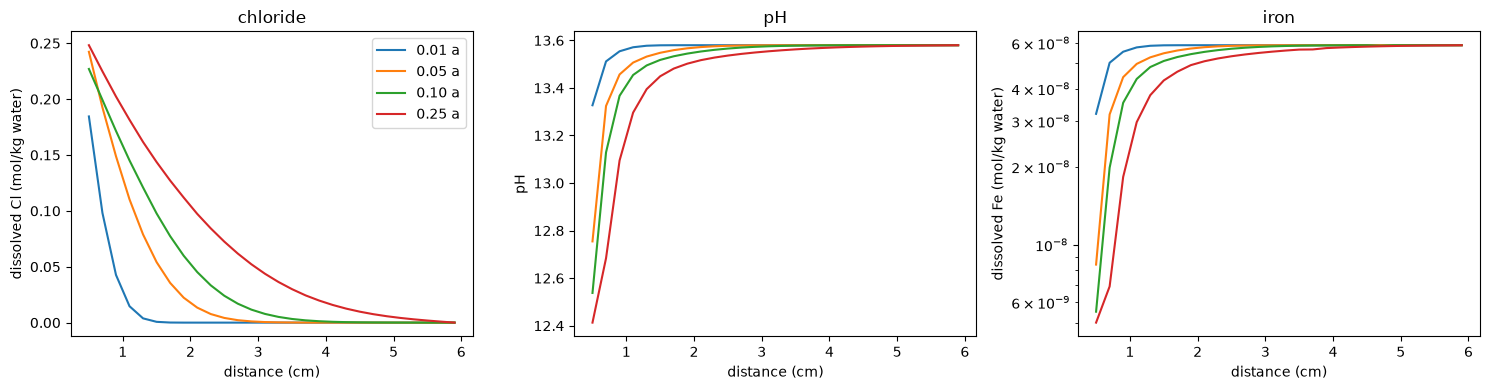

In [5]:
dx = L / N
x = (np.arange(N) + 0.5) * dx * 100   # node centres, cm
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for y, s in snap.items():
    ax[0].plot(x[2:], s["Cl"][2:], label=f"{s['t']:.2f} a")
    ax[1].plot(x[2:], s["pH"][2:])
    ax[2].plot(x[2:], s["Fe"][2:])
ax[0].set(xlabel="distance (cm)", ylabel="dissolved Cl (mol/kg water)", title="chloride"); ax[0].legend()
ax[1].set(xlabel="distance (cm)", ylabel="pH", title="pH")
ax[2].set(xlabel="distance (cm)", ylabel="dissolved Fe (mol/kg water)", title="iron", yscale="log")
plt.tight_layout(); plt.show()

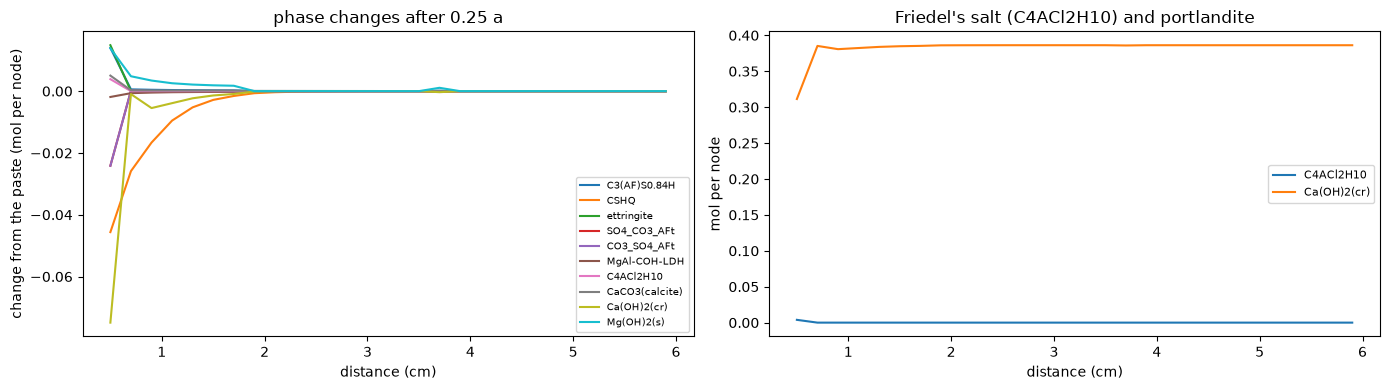

In [6]:
last = snap[max(snap)]
# change of each solid phase from the unreacted paste (the last paste node), in mol per node
change = {p: last["ph"][p] - last["ph"][p][-2] for p in names if p != "aq_sit" and abs(last["ph"][p] - last["ph"][p][-2]).max() > 2e-4}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for p, d in change.items():
    ax[0].plot(x[2:], d[2:], label=p)
ax[0].set(xlabel="distance (cm)", ylabel="change from the paste (mol per node)", title=f"phase changes after {last['t']:.2f} a")
ax[0].legend(fontsize=7)
for p in ("C4ACl2H10", "Ca(OH)2(cr)"):
    ax[1].plot(x[2:], last["ph"][p][2:], label=p)
ax[1].set(xlabel="distance (cm)", ylabel="mol per node", title="Friedel's salt (C4ACl2H10) and portlandite")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Notes

- **What happens.** The paste buffers the acid FeCl3 solution: only the first 1 to 2 cm change (portlandite and C-S-H dissolve, Friedel's
  salt forms), the chloride goes further as dissolved Cl. The iron is taken up near the inlet; dissolved Fe is about 1e-8 mol/kg at pH 13.
- **Limits of this setup.** 'A' mode moves only the aqueous phase and needs the same aqueous mass in all nodes (known limit).
  The solids stay in place. The porosity (0.04) is a transport value; it is not changed by the precipitation and dissolution in the
  nodes (the benchmark has porosity-diffusion coupling only in its sensitivity case S2).
- **All solutes have the same diffusion coefficient**, as in the benchmark reference case (no electrochemical coupling).
- **Run time.** 0.25 years (198 steps, 30 nodes) take about 3 minutes. A longer time or finer nodes need more steps:
  the time step goes with `dx²`.
- **Chemistry.** The system file is one equilibrium export. To change the phases or the species (for example more Fe
  phases), open the project `PCCEM26_Cl` in GEM-Selektor and export a new system.